# Листок 3
## Прикладные дифференциальные уравнения
Босарев Евгений Вадимович  
ЭФБО-11-24

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.integrate import solve_ivp
from scipy.special import ellipk
from IPython.display import display, HTML
from pathlib import Path

FIG = Path('рисунки_листок_3')
FIG.mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 80
g = 9.81


## 3.1 Равномерный вертикальный спуск
Ось $y$ направлена вверх; $s=y_0-y\ge0$, $\dot y=-c<0$, $s=ct$. Для гладкой неподвижной кривой реакция опоры перпендикулярна скорости. Второй закон Ньютона имеет вид $m\ddot{\mathbf r}=m(0,-g)+\mathbf N$. Умножая его на скорость и используя $\mathbf N\cdot\dot{\mathbf r}=0$, получаем закон энергии: $\dot x^2+c^2=v_0^2+2gs$. Если в верхней точке $\dot x=0$, то $v_0=c$, $\dot x=\sqrt{2gs}$. Значит,
$$\frac{dx}{ds}=\frac{\sqrt{2gs}}c,\quad x-x_0=\frac{2\sqrt{2g}}{3c}s^{3/2},\quad y=y_0-\left(\frac{3c(x-x_0)}{2\sqrt{2g}}\right)^{2/3}.$$
При $t=0$ вертикальная скорость уже равна $-c$.

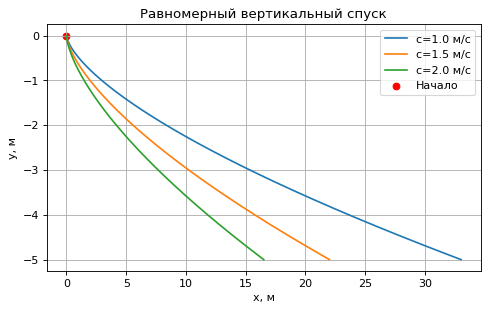

In [2]:
def uniform_x(s, c, x0=0):
    return x0 + 2*np.sqrt(2*g)*s**1.5/(3*c)

s = np.linspace(0, 5, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for c in [1.0, 1.5, 2.0]:
    ax.plot(uniform_x(s, c), -s, label=f'c={c} м/с')
ax.scatter([0], [0], color='red', label='Начало')
ax.set(xlabel='x, м', ylabel='y, м', title='Равномерный вертикальный спуск')
ax.grid(); ax.legend()
fig.savefig(FIG/'3_1_спуск.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(uniform_x(s, 1.5), -s, color='navy')
point, = ax.plot([], [], 'ro', ms=9)
info = ax.text(.02, .96, '', transform=ax.transAxes, va='top')
ax.set(xlim=(0, uniform_x(5, 1.5)*1.05), ylim=(-5.3, .3),
       xlabel='x, м', ylabel='y, м')
ax.grid()
def update1(k):
    depth = 5*k/49
    point.set_data([uniform_x(depth, 1.5)], [-depth])
    info.set_text(f't={depth/1.5:.2f} с; y={-depth:.2f} м; vy=-1.5 м/с')
    return point, info
anim = FuncAnimation(fig, update1, frames=50, interval=80, blit=True)
anim.save(FIG/'3_1_спуск.gif', writer=PillowWriter(fps=12))
display(HTML(anim.to_jshtml())); plt.close(fig)


## 3.2 Бильярд в прямоугольнике
При ударе о вертикальную стенку меняется знак $v_x$, при ударе о горизонтальную — знак $v_y$. Между ударами $ddot x=ddot y=0$. Развёртка отражений превращает ломаную в прямую $(x_0+v_xt,y_0+v_yt)$ на сетке копий прямоугольника. Координата внутри стола длины $a$ выражается как $R_a(u)=a-|u\bmod 2a-a|$. Поэтому $(x,y)=(R_a(x_0+v_xt),R_b(y_0+v_yt))$. При рациональном отношении $(v_x/a)/(v_y/b)$ траектория периодична; при иррациональном обычно плотно заполняет стол. Кинетическая энергия постоянна между ударами и сохраняется при идеальном отражении.

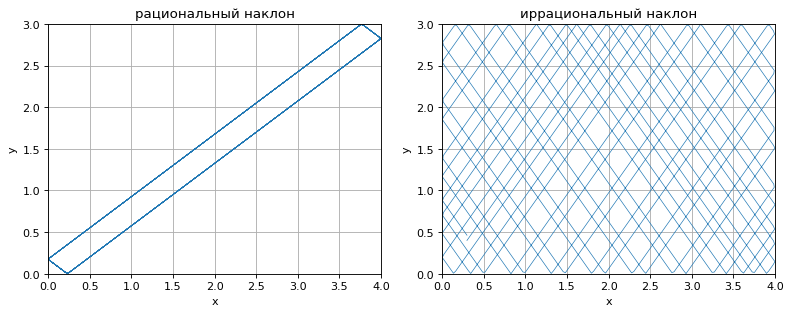

In [3]:
def reflect(u, length):
    return length - np.abs(np.mod(u, 2*length)-length)

a, b = 4., 3.
tt = np.linspace(0, 80, 3000)
cases = [(1., .75, 'рациональный наклон'), (1., np.sqrt(2), 'иррациональный наклон')]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (vx, vy, title) in zip(axes, cases):
    ax.plot(reflect(.3+vx*tt, a), reflect(.4+vy*tt, b), lw=.6)
    ax.set(xlim=(0,a), ylim=(0,b), title=title, xlabel='x', ylabel='y')
    ax.set_aspect('equal'); ax.grid()
fig.tight_layout(); fig.savefig(FIG/'3_2_бильярд.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.set(xlim=(0,a), ylim=(0,b), xlabel='x', ylabel='y', title='Два бильярдных шара')
ax.set_aspect('equal'); ax.grid()
lines = [ax.plot([], [], lw=1)[0] for _ in cases]
points = [ax.plot([], [], 'o', ms=8)[0] for _ in cases]
def update2(k):
    t = np.linspace(0, k*.4, max(k+1, 2))
    for i, (vx, vy, _) in enumerate(cases):
        x, y = reflect(.3+vx*t, a), reflect(.4+vy*t, b)
        lines[i].set_data(x, y); points[i].set_data([x[-1]], [y[-1]])
    return lines + points
anim = FuncAnimation(fig, update2, frames=60, interval=80, blit=True)
anim.save(FIG/'3_2_бильярд.gif', writer=PillowWriter(fps=12))
display(HTML(anim.to_jshtml())); plt.close(fig)


## 3.3 Цепная линия
Пусть $
ho$ — масса единицы длины цепи, $H$ — горизонтальная составляющая натяжения, а $s$ — длина от нижней точки. Равновесие участка даёт $T_y=\rho gs$, поэтому $y'=T_y/H$. Из $ds/dx=\sqrt{1+y'^2}$ следует $y''=(\rho g/H)\sqrt{1+y'^2}$. Обозначив $a=H/(\rho g)$ и взяв $y'(x_0)=0$, интегрируем: $y(x)=a\cosh((x-x_0)/a)+C$. Параметр $a$ определяют из длины цепи и расстояния между точками подвеса.

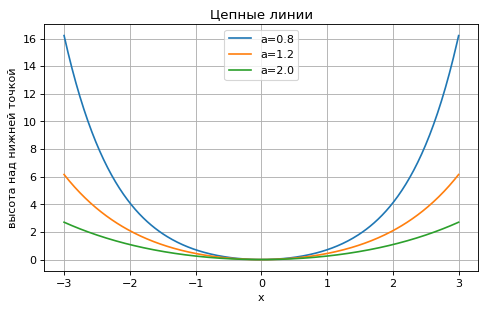

In [4]:
xx = np.linspace(-3, 3, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for aa in [0.8, 1.2, 2.0]:
    ax.plot(xx, aa*(np.cosh(xx/aa)-1), label=f'a={aa}')
ax.set(xlabel='x', ylabel='высота над нижней точкой', title='Цепные линии')
ax.legend(); ax.grid(); fig.savefig(FIG/'3_3_цепная_линия.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
line, = ax.plot([], [], lw=2)
ax.set(xlim=(-3,3), ylim=(0,18), xlabel='x', ylabel='y', title='Изменение натяжения H')
ax.grid()
def update3(k):
    aa = .8 + 1.8*k/49
    line.set_data(xx, aa*(np.cosh(xx/aa)-1))
    ax.set_title(f'Цепная линия: a={aa:.2f}')
    return line,
anim = FuncAnimation(fig, update3, frames=50, interval=80, blit=False)
anim.save(FIG/'3_3_цепная_линия.gif', writer=PillowWriter(fps=12))
display(HTML(anim.to_jshtml())); plt.close(fig)


## 3.4 Таутохронная кривая
Для перевёрнутой циклоиды $x=a(\theta+\sin\theta)$, $y=a(1-\cos\theta)$, $-\pi\le\theta\le\pi$, нижняя точка соответствует $\theta=0$. Знаковая длина дуги от неё равна $s=4a\sin(\theta/2)$, поэтому $y=s^2/(8a)$. Уравнение движения вдоль дуги $\ddot s=-g\,dy/ds$ принимает вид $\ddot s+g s/(4a)=0$. Если тело отпущено без начальной скорости, $s=s_0\cos(\sqrt{g/(4a)}t)$. Время достижения нижней точки $t=\pi\sqrt{a/g}$ от начального положения не зависит.

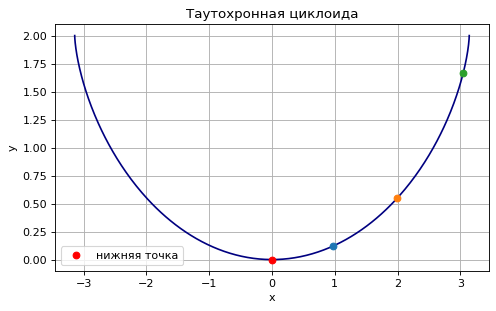

In [5]:
a_c = 1.0
theta = np.linspace(-np.pi, np.pi, 400)
cx = a_c*(theta+np.sin(theta)); cy = a_c*(1-np.cos(theta))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cx, cy, color='navy')
for start in [.5, 1.1, 2.3]:
    ax.plot(a_c*(start+np.sin(start)), a_c*(1-np.cos(start)), 'o')
ax.plot([0], [0], 'ro', label='нижняя точка')
ax.set(xlabel='x', ylabel='y', title='Таутохронная циклоида')
ax.grid(); ax.legend(); fig.savefig(FIG/'3_4_таутохрона.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cx, cy, color='gray'); starts = [.5, 1.1, 2.3]
balls = [ax.plot([], [], 'o', ms=9)[0] for _ in starts]
ax.set(xlim=(-3.3,3.3), ylim=(-.1,2.2), xlabel='x', ylabel='y')
ax.grid(); common_time = np.pi*np.sqrt(a_c/g)
def update4(k):
    t = common_time*k/49
    for ball, start in zip(balls, starts):
        s0 = 4*a_c*np.sin(start/2)
        sk = s0*np.cos(np.sqrt(g/(4*a_c))*t)
        th = 2*np.arcsin(np.clip(sk/(4*a_c), -1, 1))
        ball.set_data([a_c*(th+np.sin(th))], [a_c*(1-np.cos(th))])
    ax.set_title(f'Время {t:.2f} с; все прибудут через {common_time:.2f} с')
    return balls
anim = FuncAnimation(fig, update4, frames=50, interval=80, blit=False)
anim.save(FIG/'3_4_таутохрона.gif', writer=PillowWriter(fps=12))
display(HTML(anim.to_jshtml())); plt.close(fig)


## 3.5 Маятник
При угле $\theta$ от нижнего положения закон Ньютона вдоль дуги даёт $\ddot\theta+(g/l)\sin\theta=0$. Энергия $E=ml^2\dot\theta^2/2+mgl(1-\cos\theta)$ постоянна. При малых углах $\sin\theta\approx\theta$ и период $T_0=2\pi\sqrt{l/g}$. Для амплитуды $\theta_0$ точный период $T=4\sqrt{l/g}\,K(\sin^2(\theta_0/2))$, где $K$ — полный эллиптический интеграл. При $\theta_0\to\pi$ период стремится к бесконечности; граница между колебанием и вращением имеет энергию $2mgl$.

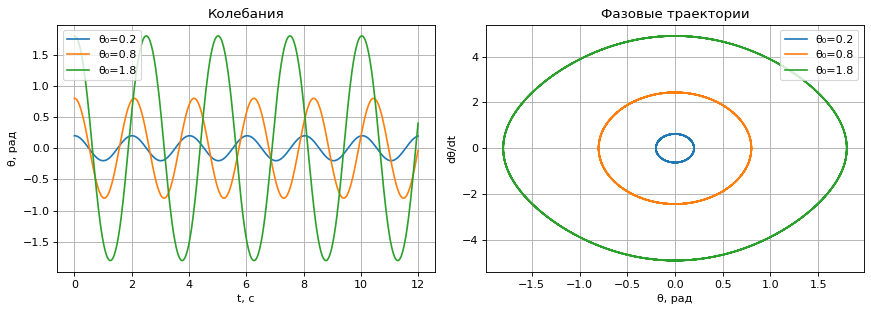

θ₀=0.2: точный период 2.0111 c, малые углы 2.0061 c
θ₀=0.8: точный период 2.0894 c, малые углы 2.0061 c
θ₀=1.8: точный период 2.5089 c, малые углы 2.0061 c
Относительное отклонение энергии: 1.30e-08


In [6]:
length, mass = 1., 1.
angles = [.2, .8, 1.8]
time = np.linspace(0, 12, 500)
def pendulum_rhs(t, state):
    return [state[1], -g/length*np.sin(state[0])]
solutions = [solve_ivp(pendulum_rhs, (0,12), [angle,0], t_eval=time,
                       rtol=1e-9, atol=1e-10).y for angle in angles]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for angle, sol in zip(angles, solutions):
    axes[0].plot(time, sol[0], label=f'θ₀={angle}')
    axes[1].plot(sol[0], sol[1], label=f'θ₀={angle}')
axes[0].set(xlabel='t, с', ylabel='θ, рад', title='Колебания')
axes[1].set(xlabel='θ, рад', ylabel='dθ/dt', title='Фазовые траектории')
for ax in axes: ax.grid(); ax.legend()
fig.tight_layout(); fig.savefig(FIG/'3_5_маятник.png', bbox_inches='tight'); plt.show()
for angle in angles:
    exact = 4*np.sqrt(length/g)*ellipk(np.sin(angle/2)**2)
    print(f'θ₀={angle:.1f}: точный период {exact:.4f} c, малые углы {2*np.pi*np.sqrt(length/g):.4f} c')
energy = .5*mass*length**2*solutions[1][1]**2 + mass*g*length*(1-np.cos(solutions[1][0]))
print(f'Относительное отклонение энергии: {np.ptp(energy)/np.mean(energy):.2e}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([-1.2,1.2],[0,0], color='black')
rods = [ax.plot([], [], '-', lw=2)[0] for _ in angles]
balls = [ax.plot([], [], 'o', ms=10)[0] for _ in angles]
ax.set(xlim=(-1.2,1.2), ylim=(-1.2,.2), xlabel='x', ylabel='y', title='Маятники')
ax.set_aspect('equal'); ax.grid()
def update5(k):
    idx = int(k*(len(time)-1)/59)
    for rod, ball, sol in zip(rods, balls, solutions):
        th = sol[0,idx]; x, y = length*np.sin(th), -length*np.cos(th)
        rod.set_data([0,x],[0,y]); ball.set_data([x],[y])
    ax.set_title(f'Маятники, t={time[idx]:.2f} с')
    return rods + balls
anim = FuncAnimation(fig, update5, frames=60, interval=80, blit=False)
anim.save(FIG/'3_5_маятник.gif', writer=PillowWriter(fps=12))
display(HTML(anim.to_jshtml())); plt.close(fig)
